# 02. 기술통계 (코딩 2 작업 4)

**목적:** 모형에 들어가기 전에 **원자료 → 분석 표본 → 단순 패턴**의 연결을 보여 준다 (교수님 평가 기준: 원자료와의 관계 제시).

- 입력: `out/analysis_table_v2.parquet` (1행 = 가게 1곳, 2013~2022년 개업), `out/1127_본분석_v1.xlsx`의 `표본 요약` 시트
- 개인정보 보호: 상호·지번·관리번호·좌표 열은 **읽지 않는다**. 표는 구 단위까지만 집계한다.
- 모든 비율은 **연관**을 보여 줄 뿐이며 원인을 뜻하지 않는다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if any(f == z.name for z in font_manager.fontManager.ttflist):
        plt.rcParams['font.family'] = f; break
plt.rcParams['axes.unicode_minus'] = False

BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = BASE / 'out'
COLS = ['prior_closures', 'prior_closures_cat', 'duration_days', 'event_ours', 'dead_3y',
        'single_unit_site', 'gu', 'open_year', 'area_rq8']          # 상호·주소·좌표 열은 읽지 않음
t = pd.read_parquet(OUT / 'analysis_table_v2.parquet', columns=COLS)
main = t[t['single_unit_site']].copy()
main['grp'] = np.where(main['prior_closures'] >= 2, '2회 이상', main['prior_closures'].astype(int).astype(str) + '회')
print(f'전체 {len(t):,}곳 / 단일 점포 칸 {len(main):,}곳')

전체 111,484곳 / 단일 점포 칸 57,842곳


## 1. 표본 흐름
| 단계 | 기준 | 근거 |
| --- | --- | --- |
| 전체 | 2013~2022년 개업 일반음식점 (서울) | 3년 이전 폐업 창이 2010년 이후 자료 안에 들어오도록 |
| 단일 점포 칸 | 같은 층에 동시에 영업한 가게가 1곳 (30일 이하 겹침은 양도로 봄) | 결정 D1: 푸드코트처럼 한 층에 여러 가게가 있는 칸은 '칸 = 한 자리' 정의가 맞지 않음 |
| 분석 표본 | 위 + M4 통제변수 결측 없음 + 생존기간 > 0 | 모든 모형(M0~M4)을 같은 표본으로 비교하기 위함 |

In [2]:
summ = pd.read_excel(OUT / '1127_본분석_v1.xlsx', sheet_name='표본 요약')
final = summ[summ['이전 폐업'] == '전체'].iloc[0]
flow = pd.DataFrame({
    '단계': ['전체 개업 (2013~2022)', '단일 점포 칸 (D1)', '분석 표본 (결측 제외)'],
    '가게 수': [len(t), len(main), int(final['가게 수'])],
    '진짜 폐업': [int(t['event_ours'].sum()), int(main['event_ours'].sum()), int(final['진짜 폐업'])]})
flow['전 단계 대비 (%)'] = (flow['가게 수'] / flow['가게 수'].shift(1) * 100).round(1)
flow

,단계,가게 수,진짜 폐업,전 단계 대비 (%)
0,전체 개업 (2013~2022),111484,69246,NaN
1,단일 점포 칸 (D1),57842,33896,51.9
2,분석 표본 (결측 제외),56224,32824,97.2


## 2. 이전 폐업 횟수별 3년 안 폐업률
(가) 전체 표, (나) 단일 점포 칸, (다) 분석 표본(`표본 요약` 시트). 4회 이상 집단이 (가)에서만 크게 높은 것은 1절의 푸드코트형 칸(한 층에 가게가 수십 곳)이 섞인 영향이다 (결정 D1).

양도 규칙은 결정 D9(60일 안 같은 상호 재입점 = 양도)를 따른다.

,가게수,폐업률(%)
(가) 전체: 이전 폐업,,
0,81788,29.8
1,18065,35.8
2,4794,39.7
3,1900,42.0
4+,4937,55.6


,가게수,폐업률(%)
(나) 단일 점포 칸: 이전 폐업,,
0회,48748,28.3
1회,8123,34.1
2회 이상,971,39.6


,(다) 분석 표본: 이전 폐업,가게 수,진짜 폐업,3년 안 폐업률(%)
0,0번,47210,27394,28.1
1,1번,8049,4810,34.0
2,2번 이상,965,620,39.5
3,전체,56224,32824,29.2


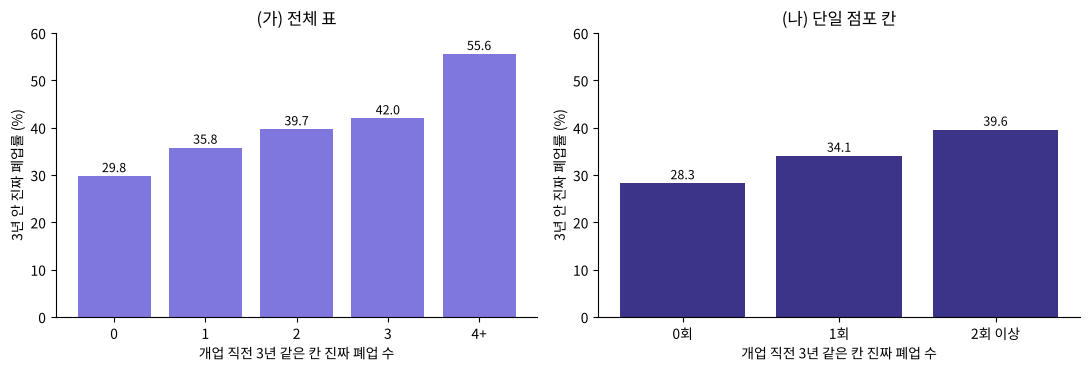

In [3]:
a = (t.groupby('prior_closures_cat')['dead_3y'].agg(가게수='size', 폐업률='mean')
       .reindex(['0', '1', '2', '3', '4+']))
a['폐업률(%)'] = (a.pop('폐업률') * 100).round(1)
b = main.groupby('grp')['dead_3y'].agg(가게수='size', 폐업률='mean').reindex(['0회', '1회', '2회 이상'])
b['폐업률(%)'] = (b.pop('폐업률') * 100).round(1)
display(a.rename_axis('(가) 전체: 이전 폐업')); display(b.rename_axis('(나) 단일 점포 칸: 이전 폐업'))
display(summ.rename(columns={'이전 폐업': '(다) 분석 표본: 이전 폐업'}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(a.index, a['폐업률(%)'], color='#7F77DD'); axes[0].set_title('(가) 전체 표')
axes[1].bar(b.index, b['폐업률(%)'], color='#3C3489'); axes[1].set_title('(나) 단일 점포 칸')
for ax, s in zip(axes, [a, b]):
    for i, v in enumerate(s['폐업률(%)']): ax.text(i, v + 0.8, f'{v}', ha='center', fontsize=9)
    ax.set_ylabel('3년 안 진짜 폐업률 (%)'); ax.set_xlabel('개업 직전 3년 같은 칸 진짜 폐업 수'); ax.set_ylim(0, 60)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 3. Kaplan–Meier 생존곡선 (단일 점포 칸)
통제변수가 없는 단순 비교다. 통제 후 결과는 본분석(M0~M4)과 `fig_예측생존곡선_M2.png`를 본다.

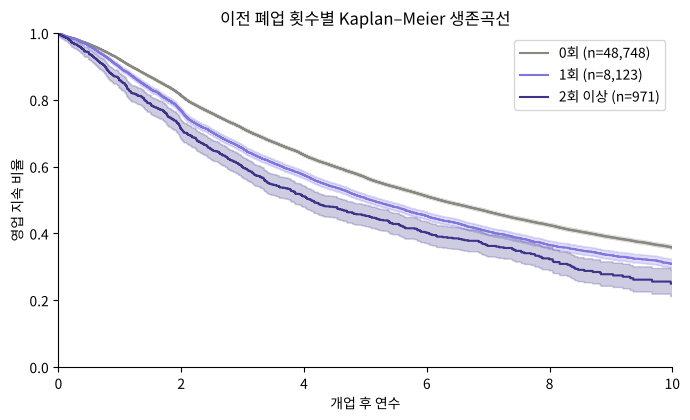

log-rank 검정 (3집단): 카이제곱 = 183.6, 자유도 = 2, p = 1.38e-40


In [4]:
fig, ax = plt.subplots(figsize=(7, 4.3))
for g, c in zip(['0회', '1회', '2회 이상'], ['#888780', '#7F77DD', '#3C3489']):
    s = main[main['grp'] == g]
    KaplanMeierFitter().fit(s['duration_days'] / 365.25, s['event_ours'], label=f'{g} (n={len(s):,})').plot_survival_function(ax=ax, color=c, ci_show=True)
ax.set_xlim(0, 10); ax.set_ylim(0, 1); ax.set_xlabel('개업 후 연수'); ax.set_ylabel('영업 지속 비율')
ax.set_title('이전 폐업 횟수별 Kaplan–Meier 생존곡선'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
lr = multivariate_logrank_test(main['duration_days'], main['grp'], main['event_ours'])
print(f'log-rank 검정 (3집단): 카이제곱 = {lr.test_statistic:.1f}, 자유도 = 2, p = {lr.p_value:.2e}')

## 4. 개업 연도별
2022년 개업 가게도 3년 관찰이 가능하므로(관찰 종료 2026-11-05) 연도 간 비교는 `dead_3y`로 한다.

,가게수,3년 안 폐업률(%),이전 폐업 1회 이상(%)
open_year,,,
2013,8570,26.7,13.0
2014,10026,28.6,15.1
2015,10128,28.9,18.5
2016,10038,30.3,19.9
2017,11060,30.6,23.9
2018,11352,31.7,26.0
2019,12147,32.1,30.1
2020,12745,35.0,33.3
2021,13078,37.9,36.3


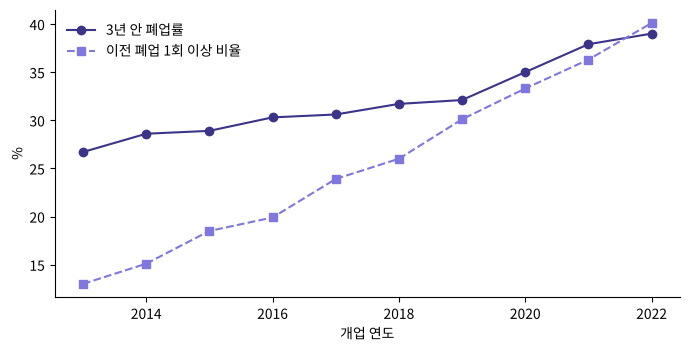

In [5]:
yr = t.groupby('open_year').agg(가게수=('dead_3y', 'size'), 폐업률=('dead_3y', 'mean'),
                                이전폐업1회이상=('prior_closures', lambda s: (s >= 1).mean()))
yr[['폐업률', '이전폐업1회이상']] = (yr[['폐업률', '이전폐업1회이상']] * 100).round(1)
yr = yr.rename(columns={'폐업률': '3년 안 폐업률(%)', '이전폐업1회이상': '이전 폐업 1회 이상(%)'})
display(yr)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(yr.index, yr['3년 안 폐업률(%)'], 'o-', color='#3C3489', label='3년 안 폐업률')
ax.plot(yr.index, yr['이전 폐업 1회 이상(%)'], 's--', color='#7F77DD', label='이전 폐업 1회 이상 비율')
ax.set_xlabel('개업 연도'); ax.set_ylabel('%'); ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 5. 지역 유형별 (`area_rq8`)

In [6]:
ar = t.groupby('area_rq8', dropna=False).agg(가게수=('dead_3y', 'size'), 폐업률=('dead_3y', 'mean'),
                                          이전폐업1회이상=('prior_closures', lambda s: (s >= 1).mean()))
ar[['폐업률', '이전폐업1회이상']] = (ar[['폐업률', '이전폐업1회이상']] * 100).round(1)
ar.rename(columns={'폐업률': '3년 안 폐업률(%)', '이전폐업1회이상': '이전 폐업 1회 이상(%)'})

,가게수,3년 안 폐업률(%),이전 폐업 1회 이상(%)
area_rq8,,,
골목상권,35280,33.4,22.3
발달상권,45616,30.9,30.4
상권밖,20145,34.5,26.9
전통시장,9578,31.9,24.1
NaN,865,43.0,30.2


## 6. 구별 (25개 구, 3년 안 폐업률 순)
구 단위 집계만 제시한다. 상호·주소는 출력하지 않는다.

In [7]:
gu = t.groupby('gu').agg(가게수=('dead_3y', 'size'), 폐업률=('dead_3y', 'mean'),
                         이전폐업1회이상=('prior_closures', lambda s: (s >= 1).mean()))
gu[['폐업률', '이전폐업1회이상']] = (gu[['폐업률', '이전폐업1회이상']] * 100).round(1)
gu = gu.sort_values('폐업률', ascending=False).rename(columns={'폐업률': '3년 안 폐업률(%)', '이전폐업1회이상': '이전 폐업 1회 이상(%)'})
print(f'구 수: {len(gu)}'); gu

구 수: 25


,가게수,3년 안 폐업률(%),이전 폐업 1회 이상(%)
gu,,,
관악구,5247,39.1,27.4
강동구,3303,37.2,21.2
양천구,3319,36.5,32.0
은평구,3912,35.8,25.1
강남구,13124,35.7,32.8
강서구,6311,35.0,31.9
광진구,3925,34.8,25.2
동대문구,3674,33.7,22.9
금천구,2728,33.6,32.6


## 7. 관찰 결과 (숫자만, 원인 해석 없음)
- 분석 표본은 전체 111,484곳에서 단일 점포 칸 57,842곳(51.9%), 결측 제외 56,224곳으로 줄었다.
- 단일 점포 칸에서 개업 직전 3년 같은 칸 진짜 폐업이 0회 / 1회 / 2회 이상인 가게의 3년 안 폐업률은 28.3% / 34.1% / 39.6%로 단조 증가했다 (log-rank p < 0.001).
- 전체 표에서 4회 이상 집단의 폐업률(55.6%)이 유독 높은 것은 푸드코트형 칸이 섞인 영향이므로 주분석에서 제외한 근거가 된다 (결정 D1).
- 개업 연도가 늦을수록 3년 안 폐업률(2013년 26.7% → 2022년 39.0%)과 이전 폐업 1회 이상 비율(13.0% → 40.1%)이 함께 높아졌다. 그래서 본분석은 개업 연도 더미를 통제한다.
- 구별 3년 안 폐업률은 20.5%(종로구) ~ 39.1%(관악구)로 차이가 커서, 본분석에서 동네 폐업률을 통제하는 근거가 된다.